**Setup**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
if REPO not in sys.path:
    sys.path.append(REPO)
importlib.invalidate_caches()          # prend en compte les nouveaux fichiers après un pull
!pip install -q -r requirements.txt

from src.config import *
set_seed(42)
prepare_data()
print(device, DATA_ROOT)

Mounted at /content/drive
Cloning into '/content/anomaly-mvtec'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 69 (delta 21), reused 56 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 12.85 MiB | 16.08 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/anomaly-mvtec
Données prêtes : ['carpet', 'screw', 'cable']
cuda /content/mvtec


In [3]:
import torch, numpy as np
from src.data import *
from src.scoring import *
from src.metrics import *

**Cellule 2 : imports et configuration**

In [4]:
import numpy as np, pandas as pd, torch, time
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src.data import *
from src.scoring import *
from src.metrics import evaluate          # le cadre commun (pas celui du notebook 03)
from src.models.dino import DinoDetector

IMG_SIZE = 224
K_LIST, K_MAIN = [1, 3, 5], 1             # K_MAIN fixé à l'avance ; les autres = ablation
SIGMA = 4
RES_DIR = f"{REPO}/results"; os.makedirs(RES_DIR, exist_ok=True)
det = DinoDetector("dino_vits8", IMG_SIZE, device)

Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall8_pretrain/dino_deitsmall8_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall8_pretrain.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 346MB/s]


**Cellule 2 : imports et configuration**

In [5]:
import time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src.data import *
from src.scoring import *
from src.metrics import evaluate
from src.models.vae import ConvVAE, vae_loss

IMG_SIZE = 128                       # ⚠️ à dire dans le rapport : SimSiam et DINO sont en 224
Z_DIM, EPOCHS, BS, LR = 128, 150, 32, 1e-3
BETAS, BETA_MAIN = [1e-3, 1e-2, 1e-1], 1e-2     # BETA_MAIN fixé à l'avance, les autres = ablation
SIGMA = 4
RES_DIR = f"{REPO}/results"; os.makedirs(RES_DIR, exist_ok=True)

**Cellule 3 : fonction d’entraînement**

In [6]:
def train_vae(cat, beta, epochs=EPOCHS):
    set_seed()
    tr, _ = list_train_val(DATA_ROOT, cat)
    ds = MVTecDataset(tr, IMG_SIZE)
    X = torch.stack([ds[i][0] for i in range(len(ds))]).to(device)      # (N,3,128,128) dans [0,1]
    model = ConvVAE(Z_DIM).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"loss": [], "rec": [], "kl": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X), device=device)
        L, R, K = [], [], []
        for i in range(0, len(X) - BS + 1, BS):
            x = X[perm[i:i + BS]]
            xr, mu, lv = model(x)
            loss, rec, kl = vae_loss(x, xr, mu, lv, beta)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            L.append(loss.item()); R.append(rec.item()); K.append(kl.item())
        hist["loss"].append(np.mean(L)); hist["rec"].append(np.mean(R)); hist["kl"].append(np.mean(K))
        if (ep + 1) % 25 == 0 or ep == 0:
            print(f"  ep {ep+1:3d} | loss {hist['loss'][-1]:.1f} | rec {hist['rec'][-1]:.1f} | KL {hist['kl'][-1]:.1f}")
    return model.eval(), hist

**Cellule 4 : expériences (3 catégories × 3 valeurs de β)**

In [7]:
vae_map_fn = lambda model: (lambda x: ((x - model(x)[0]) ** 2).mean(dim=1))   # carte = erreur de reconstruction

rows, HIST, MODELS_MAIN = [], {}, {}
for cat in CATEGORIES:
    tr, val = list_train_val(DATA_ROOT, cat)
    test_ds, val_ds = MVTecDataset(list_test(DATA_ROOT, cat), IMG_SIZE), MVTecDataset(val, IMG_SIZE)
    for beta in BETAS:
        t0 = time.time()
        print(f"\n=== VAE β={beta} | {cat} ===")
        model, hist = train_vae(cat, beta)
        torch.save(model.state_dict(), f"{CKPT_DIR}/VAE_beta{beta}_{cat}.pt")
        HIST[(cat, beta)] = hist

        maps, labels, masks = predict_maps(vae_map_fn(model), test_ds, batch_size=32, device=device)
        res = evaluate(labels, masks, maps, sigma=SIGMA, with_aupro=(beta == BETA_MAIN))
        rows.append({"model": f"VAE_beta{beta}", "category": cat, **res})
        print({a: round(float(b), 3) for a, b in res.items()}, f"| {time.time()-t0:.0f}s")

        if beta == BETA_MAIN:                       # on garde ce run pour les figures et T9
            MODELS_MAIN[cat] = (model, maps)
            test_scores = image_scores_from_maps(smooth_maps(maps, SIGMA))
            vmaps, _, _ = predict_maps(vae_map_fn(model), val_ds, batch_size=32, device=device)
            val_scores = image_scores_from_maps(smooth_maps(vmaps, SIGMA))
            np.savez_compressed(f"{CKPT_DIR}/vae_scores_{cat}.npz",
                                labels=labels, test_scores=test_scores, val_scores=val_scores)


=== VAE β=0.001 | carpet ===
  ep   1 | loss 1283.0 | rec 1282.8 | KL 265.8
  ep  25 | loss 287.9 | rec 287.5 | KL 468.6
  ep  50 | loss 166.0 | rec 165.1 | KL 874.2
  ep  75 | loss 126.3 | rec 125.4 | KL 905.7
  ep 100 | loss 93.1 | rec 92.1 | KL 965.6
  ep 125 | loss 76.2 | rec 75.2 | KL 951.8
  ep 150 | loss 68.7 | rec 67.7 | KL 929.6
{'img_auroc': 0.603, 'pix_auroc': 0.848} | 55s

=== VAE β=0.01 | carpet ===
  ep   1 | loss 1284.8 | rec 1282.7 | KL 209.1
  ep  25 | loss 294.2 | rec 292.3 | KL 190.3
  ep  50 | loss 189.3 | rec 185.5 | KL 382.9
  ep  75 | loss 146.0 | rec 142.2 | KL 372.6
  ep 100 | loss 107.5 | rec 103.3 | KL 419.1
  ep 125 | loss 86.8 | rec 82.7 | KL 408.9
  ep 150 | loss 76.2 | rec 72.1 | KL 406.8
{'img_auroc': 0.547, 'pix_auroc': 0.853, 'aupro': 0.511} | 53s

=== VAE β=0.1 | carpet ===
  ep   1 | loss 1288.2 | rec 1282.0 | KL 62.4
  ep  25 | loss 316.1 | rec 310.9 | KL 51.8
  ep  50 | loss 223.8 | rec 212.2 | KL 116.1
  ep  75 | loss 177.2 | rec 165.4 | KL 118.0

**Cellule 5 : tableau et sauvegarde**

In [8]:
df = pd.DataFrame(rows)
df.to_csv(f"{RES_DIR}/vae_results.csv", index=False)
df.to_csv(f"{CKPT_DIR}/vae_results.csv", index=False)
df.round(3)

,model,category,img_auroc,pix_auroc,aupro
0,VAE_beta0.001,carpet,0.603,0.848,NaN
1,VAE_beta0.01,carpet,0.547,0.853,0.511
2,VAE_beta0.1,carpet,0.584,0.858,NaN
3,VAE_beta0.001,screw,0.579,0.975,NaN
4,VAE_beta0.01,screw,0.631,0.975,0.891
5,VAE_beta0.1,screw,0.609,0.972,NaN
6,VAE_beta0.001,cable,0.706,0.911,NaN
7,VAE_beta0.01,cable,0.699,0.914,0.615
8,VAE_beta0.1,cable,0.701,0.922,NaN


**Cellule 6 : courbes d’entraînement**

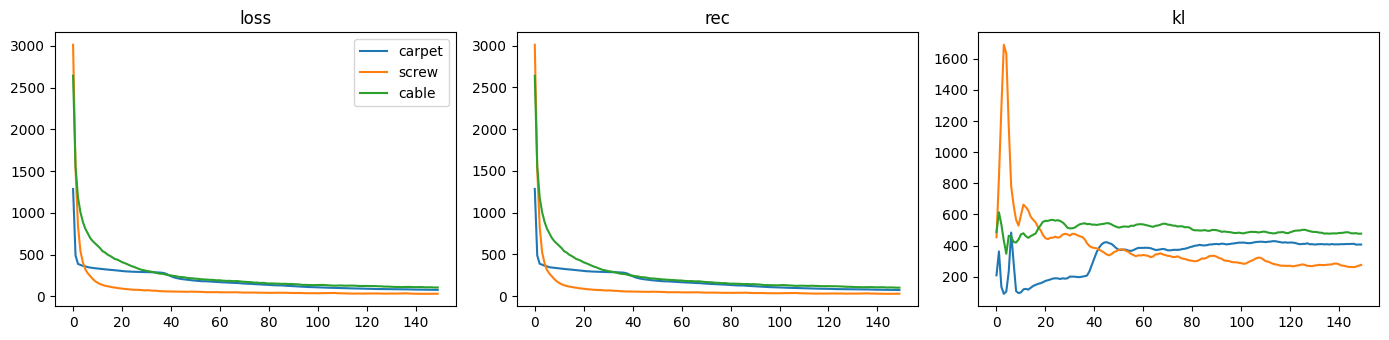

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for (cat, beta), h in HIST.items():
    if beta == BETA_MAIN:
        for a, key in zip(ax, ["loss", "rec", "kl"]):
            a.plot(h[key], label=cat); a.set_title(key)
ax[0].legend(); plt.tight_layout()
plt.savefig(f"{RES_DIR}/vae_training.png", dpi=150); plt.show()

**Cellule 7 : reconstructions et heatmaps (image / reconstruction / erreur / masque, pour une image défectueuse par catégorie)**

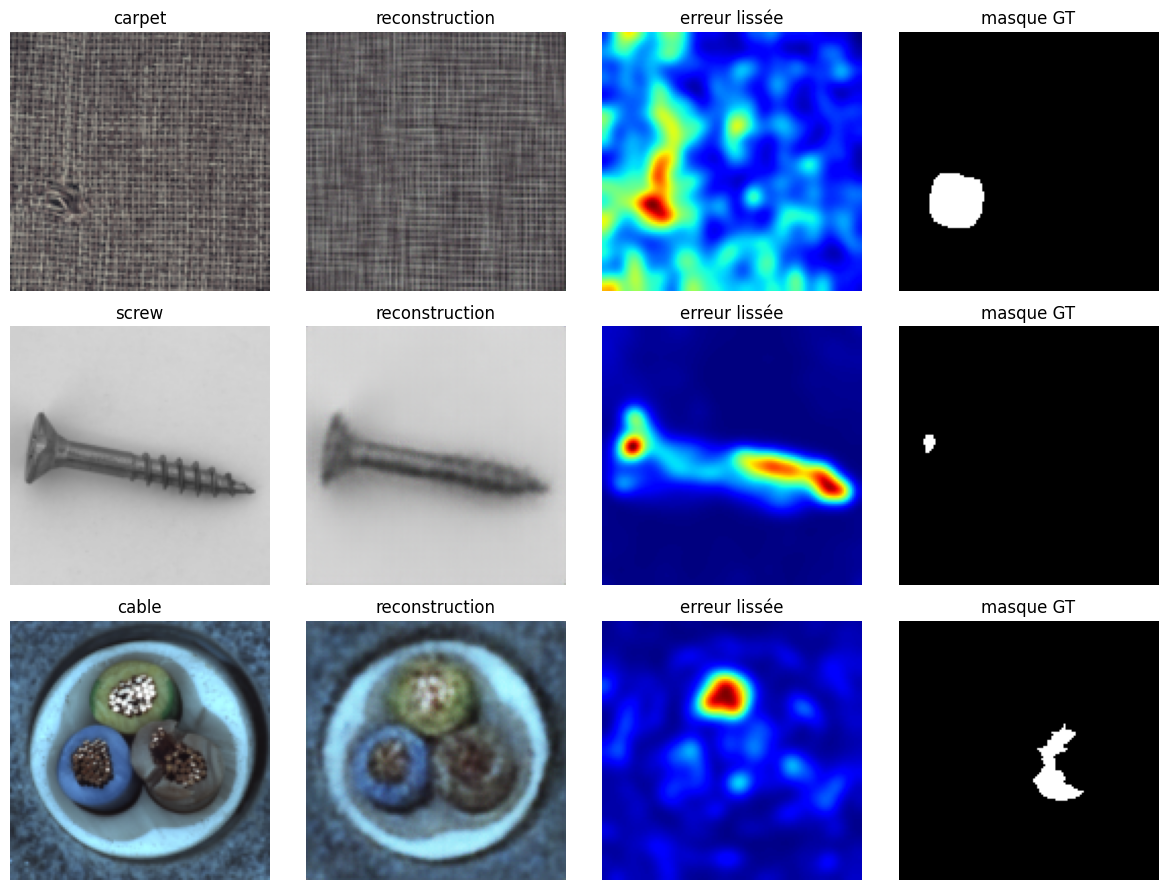

In [10]:
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for r, cat in enumerate(CATEGORIES):
    model, maps = MODELS_MAIN[cat]
    ds = MVTecDataset(list_test(DATA_ROOT, cat), IMG_SIZE)
    labels = np.array([l for _, l, _ in ds.items])
    i = np.random.RandomState(0).choice(np.where(labels == 1)[0])
    x, _, m = ds[i]
    with torch.no_grad():
        xr = model(x[None].to(device))[0][0].cpu()
    err = smooth_maps(maps[i:i+1], SIGMA)[0]
    for a, im, t, cm in zip(ax[r], [x.permute(1,2,0), xr.permute(1,2,0), err, m[0]],
                            [cat, "reconstruction", "erreur lissée", "masque GT"], [None, None, "jet", "gray"]):
        a.imshow(im, cmap=cm); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/vae_examples.png", dpi=150); plt.show()